# Training the coverage_kernel models on the real MLIP impact dataset

Loads the O/O₂-on-Al₂O₃ impact-trajectory dataset (`example_data/`, copied
from the original `coverage_experiment/coverage_model` project) and fits
both schemes coverage_kernel implements:

- **pooled** (generalizes the old "global" scheme): one shared spline-logistic
  classifier over every sampled condition at once.
- **grid** (generalizes the old "piecewise_global" scheme): one independent
  classifier per sampled (velocity, angle) cell, interpolated across the grid.

Both fitted models are saved to `models/` for the second notebook
(`monte_carlo_walk.ipynb`), which drives a coverage random walk over a much
wider (velocity, angle) sweep than was actually sampled -- including
1000 m/s and 10000-11000 m/s, outside the training range -- and validates
the models' extrapolation behavior directly against real, held-out MD data
at 11000 m/s.

The validation section below checks the fit from a few different angles: the full
sampled grid plus the 11000 m/s extrapolation point, slices through
velocity/angle at fixed coverage, and a per-condition view against the
self-consistent MC ceiling.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "python"))
sys.path.insert(0, str(Path.cwd()))

from coverage_kernel.pooled_classifier import SplineTerm, LinearTerm
from coverage_kernel.grid_classifier import AxisSpec
from coverage_kernel.coverage_model import CoveragePhysics, fit_coverage_pooled_model, fit_coverage_grid_model
from load_data import load_trajectories
from coverage_kernel.features import physics_features

## Dataset configuration

8 sampled velocities × 5 sampled angles = 40 conditions, ~2000 impacts each.
`fragment_velocities_11000.h5` exists in `example_data/` too but is
deliberately **not** included here -- it's held out entirely from training,
used only in the second notebook as an out-of-sample extrapolation check.

In [2]:
DATA_DIR = Path("example_data")
RESULTS_PATH = DATA_DIR / "impact_results" / "fragment_velocities_"
FRAMES_PATH = DATA_DIR / "starting_frames.h5"

TRAIN_VELOCITIES = [2000, 3000, 5000, 6527, 7261, 7923, 8585, 9319]   # nominal grid labels (see load_data.py)
TRAIN_ANGLES = [0, 20, 40, 60, 80]
N_SITES = 48
N_SUBSTRATE_ATOMS = 480

df = load_trajectories(str(RESULTS_PATH), str(FRAMES_PATH), TRAIN_VELOCITIES, TRAIN_ANGLES,
                        n_substrate_atoms=N_SUBSTRATE_ATOMS)
df = df[df["n_atoms"] <= 2].reset_index(drop=True)   # drop rare multi-fragment/"other" events
print(f"{len(df)} events")
df.head()

400952 events


,velocity,angle,coverage,n_atoms
0,2000.0,0.0,6,0
1,2000.0,0.0,7,0
2,2000.0,0.0,6,0
3,2000.0,0.0,5,0
4,2000.0,0.0,4,0


## Physics configuration

Outcomes: `0`=adsorption, `1`=O desorption, `2`=O₂ desorption.
Coverage delta: adsorption +1, O desorption 0, O₂ desorption -1 (it takes an
already-adsorbed atom with it). O₂ desorption is impossible at coverage 0;
adsorption is impossible once every site is full -- see `CoveragePhysics`.

In [3]:
IDX_ADS, IDX_O_DES, IDX_O2_DES = 0, 1, 2
N_CLASSES = 3
COVERAGE_DELTA = [+1, 0, -1]

physics = CoveragePhysics(n_sites=N_SITES, zeroed_zero_index=IDX_O2_DES,
                           zeroed_full_index=IDX_ADS, absorbing_full_index=IDX_O2_DES)

# true per-impact velocity/angle values (not the nominal labels) -- see load_data.load_trajectories
real_velocities = sorted(df["velocity"].unique())
real_angles = sorted(df["angle"].unique())
print("real velocities:", real_velocities)
print("real angles:", real_angles)

real velocities: [2000.0, 3000.0, 5000.0, 6527.8, 7261.3, 7923.6, 8585.9, 9319.4]
real angles: [0.0, 20.0, 40.0, 60.0, 80.0]


## Fit the pooled scheme

Physics-motivated features: coverage, normal energy `E_n = (v cosα)²`,
parallel velocity `v sinα`. Spline bases on coverage and `E_n`; `v_parallel`
kept linear. A small ceiling grid (self-consistent Monte-Carlo blend
boundary per sampled condition) is computed across the 8×5 grid and
interpolated at query time for conditions in between.

In [4]:
X_raw = np.stack([physics_features(c, v, a) for c, v, a in
                   zip(df["coverage"], df["velocity"], df["angle"])], axis=0)
y = df["n_atoms"].values

pooled_terms = [SplineTerm(0, n_knots=5, degree=2), SplineTerm(1, n_knots=5, degree=2), LinearTerm(2)]

pooled_model = fit_coverage_pooled_model(
    X_raw, y, pooled_terms, physics_features,
    n_classes=N_CLASSES, physics=physics, coverage_delta=COVERAGE_DELTA, C=1.0,
    ceiling_axes_values=[real_velocities, real_angles],
    ceiling_k=3.0, mc_steps=20000, mc_tail=8000, ceiling_n_jobs=-1,
)
print("pooled model fit done")

pooled model fit done


## Fit the grid scheme

One independent coverage-only spline-logistic classifier per sampled
(velocity, angle) cell. Angle is clipped outside its sampled range; velocity
linearly extrapolates (see `AxisSpec` -- this is what makes the 1000 m/s and
10000-11000 m/s points in the next notebook's sweep well-defined instead of
just clamping to the nearest sampled velocity).

In [5]:
event_axis_values = df[["velocity", "angle"]].values
event_features = df["coverage"].values
event_labels = df["n_atoms"].values

grid_axes = [AxisSpec(np.array(real_velocities), edge_policy="linear_extrapolate"),
             AxisSpec(np.array(real_angles), edge_policy="clip")]
grid_terms = [SplineTerm(0, n_knots=5, degree=2)]

grid_model = fit_coverage_grid_model(
    grid_axes, event_axis_values, event_features, event_labels, grid_terms,
    n_classes=N_CLASSES, physics=physics, coverage_delta=COVERAGE_DELTA, C=1.0,
    n_jobs=-1, method="pchip",
    ceiling_k=3.0, mc_steps=20000, mc_tail=8000,
)
print("grid model fit done")

grid model fit done


## Validation: fitted curves vs. binned real data

Both schemes' predicted `P(outcome | coverage)` overlaid on the binned
empirical outcome frequencies from the real trajectories, at every sampled
(velocity, angle) condition, plus one extrapolated gridpoint (11000 m/s,
80 deg) checked directly against real, held-out MD data never used in
training (see `monte_carlo_walk.ipynb` for the full extrapolation sweep).

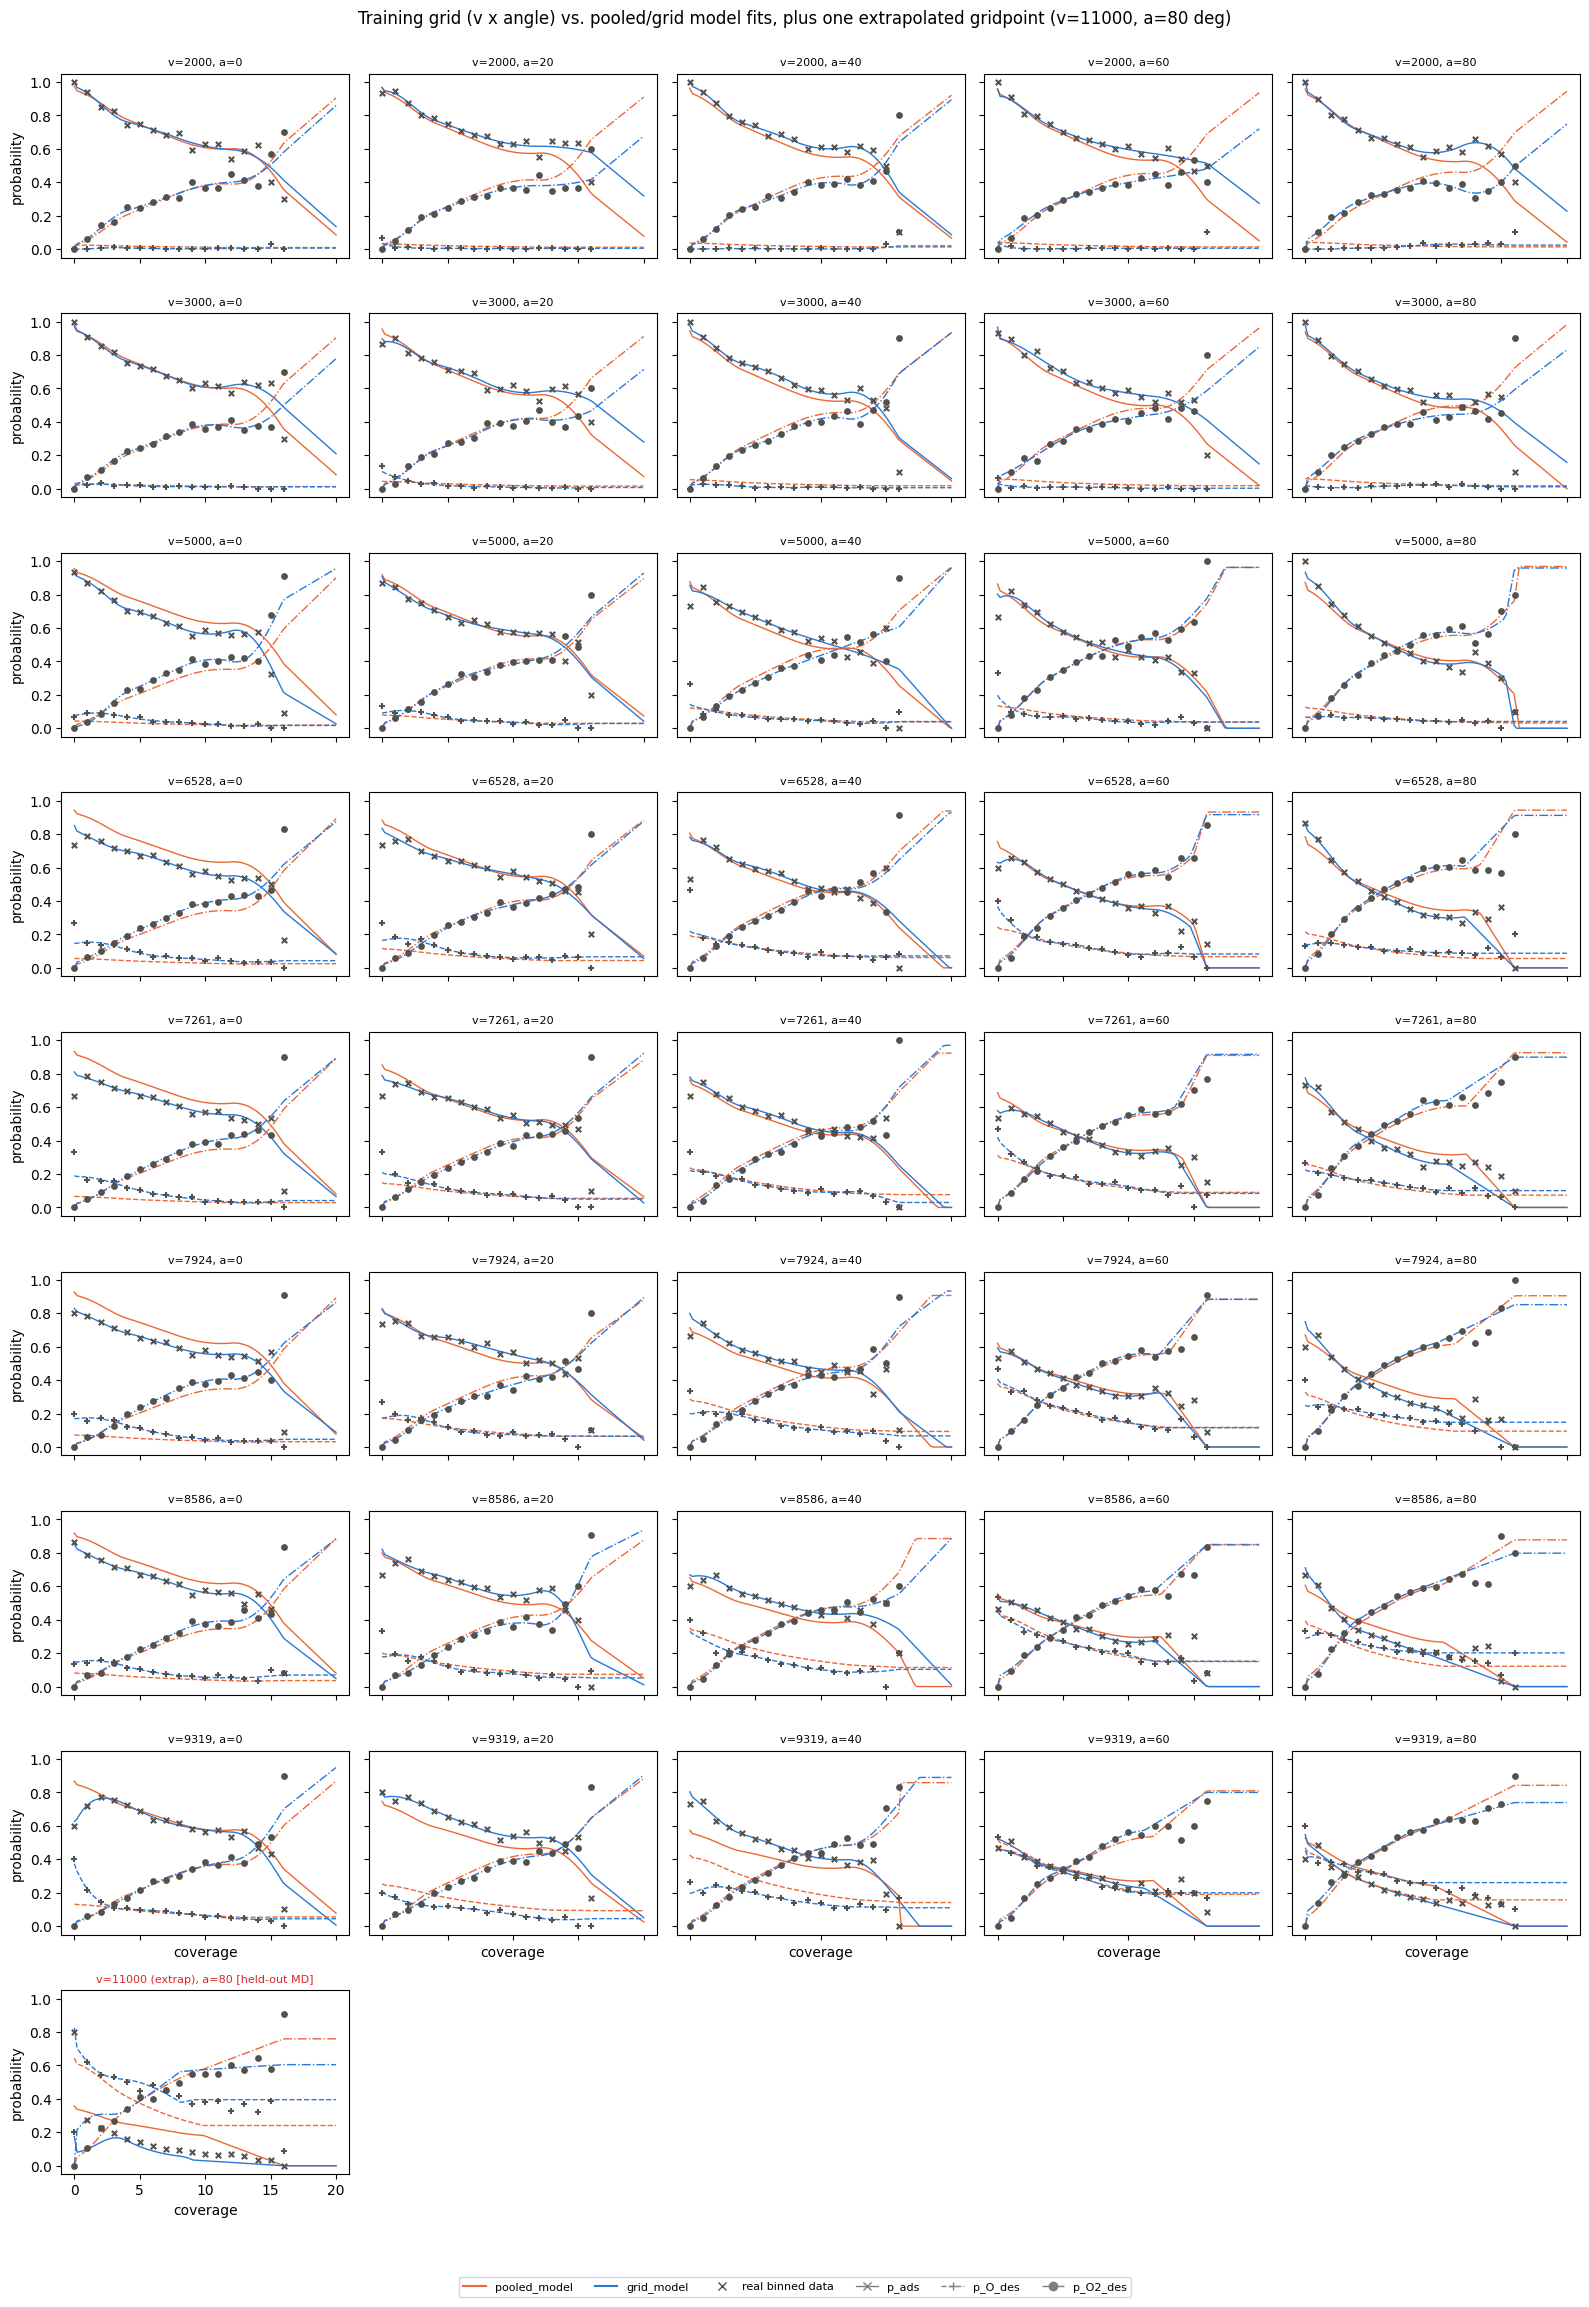

In [6]:
def bin_real(df, velocity, angle):
    sub = df[np.isclose(df["velocity"], velocity) & np.isclose(df["angle"], angle)]
    centers, probs = [], []
    for c in range(int(sub["coverage"].max()) + 1):
        m = sub[sub["coverage"] == c]
        if len(m) > 0:
            counts = m["n_atoms"].value_counts(normalize=True)
            probs.append([counts.get(0, 0.0), counts.get(1, 0.0), counts.get(2, 0.0)])
            centers.append(c)
    return np.array(centers), np.array(probs)


# extrapolated gridpoint: 11000 m/s is beyond the ~9319 m/s training max.
# fragment_velocities_11000.h5 only has real, held-out MD data at 80 deg
# (never used in training -- see monte_carlo_walk.ipynb).
df_11000 = load_trajectories(str(RESULTS_PATH), str(FRAMES_PATH), [11000], [80],
                              n_substrate_atoms=N_SUBSTRATE_ATOMS)
df_11000 = df_11000[df_11000["n_atoms"] <= 2].reset_index(drop=True)
real_velocity_11000 = float(df_11000["velocity"].unique()[0])

coverages_plot = np.linspace(0, 20, 100)
labels = ["p_ads", "p_O_des", "p_O2_des"]

POOLED_COLOR = "#eb6834"
GRID_COLOR = "#2a78d6"
REAL_COLOR = "#52514e"
LINESTYLES = ["-", "--", "-."]
MARKERS = ["x", "+", "o"]

n_rows = len(real_velocities) + 1
n_cols = len(real_angles)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.6 * n_rows),
                          sharex=True, sharey=True)

for vi, velocity_check in enumerate(real_velocities):
    for ai, angle_check in enumerate(real_angles):
        ax = axes[vi, ai]
        centers, real_probs = bin_real(df, velocity_check, angle_check)
        pooled_probs = np.array([pooled_model.probs(c, velocity_check, angle_check) for c in coverages_plot])
        grid_probs = np.array([grid_model.eval(np.array([c]), [velocity_check, angle_check]) for c in coverages_plot])

        for k in range(3):
            ax.plot(coverages_plot, pooled_probs[:, k], LINESTYLES[k], color=POOLED_COLOR, linewidth=1)
            ax.plot(coverages_plot, grid_probs[:, k], LINESTYLES[k], color=GRID_COLOR, linewidth=1)
            ax.scatter(centers, real_probs[:, k], color=REAL_COLOR, marker=MARKERS[k], s=15, zorder=5)
        ax.set_title(f"v={velocity_check:.0f}, a={angle_check:.0f}", fontsize=8)

# extra gridpoint: extrapolated velocity, checked against real held-out MD data at 80 deg
for ax in axes[-1, :]:
    ax.axis("off")
extra_ax = axes[-1, 0]
extra_ax.axis("on")
pooled_probs_extra = np.array([pooled_model.probs(c, real_velocity_11000, 80.0) for c in coverages_plot])
grid_probs_extra = np.array([grid_model.eval(np.array([c]), [real_velocity_11000, 80.0]) for c in coverages_plot])
centers, real_probs = bin_real(df_11000, real_velocity_11000, 80.0)
for k in range(3):
    extra_ax.plot(coverages_plot, pooled_probs_extra[:, k], LINESTYLES[k], color=POOLED_COLOR, linewidth=1)
    extra_ax.plot(coverages_plot, grid_probs_extra[:, k], LINESTYLES[k], color=GRID_COLOR, linewidth=1)
    extra_ax.scatter(centers, real_probs[:, k], color=REAL_COLOR, marker=MARKERS[k], s=15, zorder=5)
extra_ax.set_title(f"v={real_velocity_11000:.0f} (extrap), a=80 [held-out MD]", fontsize=8, color="C3")

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
for ax in axes[-2, :]:
    ax.set_xlabel("coverage")
extra_ax.set_xlabel("coverage")

legend_handles = (
    [plt.Line2D([0], [0], color=POOLED_COLOR, lw=1.5, label="pooled_model"),
     plt.Line2D([0], [0], color=GRID_COLOR, lw=1.5, label="grid_model"),
     plt.Line2D([0], [0], color=REAL_COLOR, marker="x", ls="", label="real binned data")]
    + [plt.Line2D([0], [0], color="gray", ls=LINESTYLES[k], marker=MARKERS[k], lw=1, label=labels[k])
       for k in range(3)]
)
fig.legend(handles=legend_handles, loc="lower center", ncol=6, fontsize=8, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("Training grid (v x angle) vs. pooled/grid model fits, "
             "plus one extrapolated gridpoint (v=11000, a=80 deg)")
plt.tight_layout(rect=[0, 0.03, 1, 0.98])
Path("hyper_plots").mkdir(exist_ok=True)
plt.savefig("hyper_plots/pooled_model_comparison.png", dpi=300)
plt.show()

## Slices through velocity and angle at fixed coverage

Same fit, sliced the other two ways: fixed coverage, varying velocity (at a
few fixed angles) or varying angle (at a few fixed velocities). Dotted
vlines mark the sampled range on that axis, so extrapolation is visible
directly.

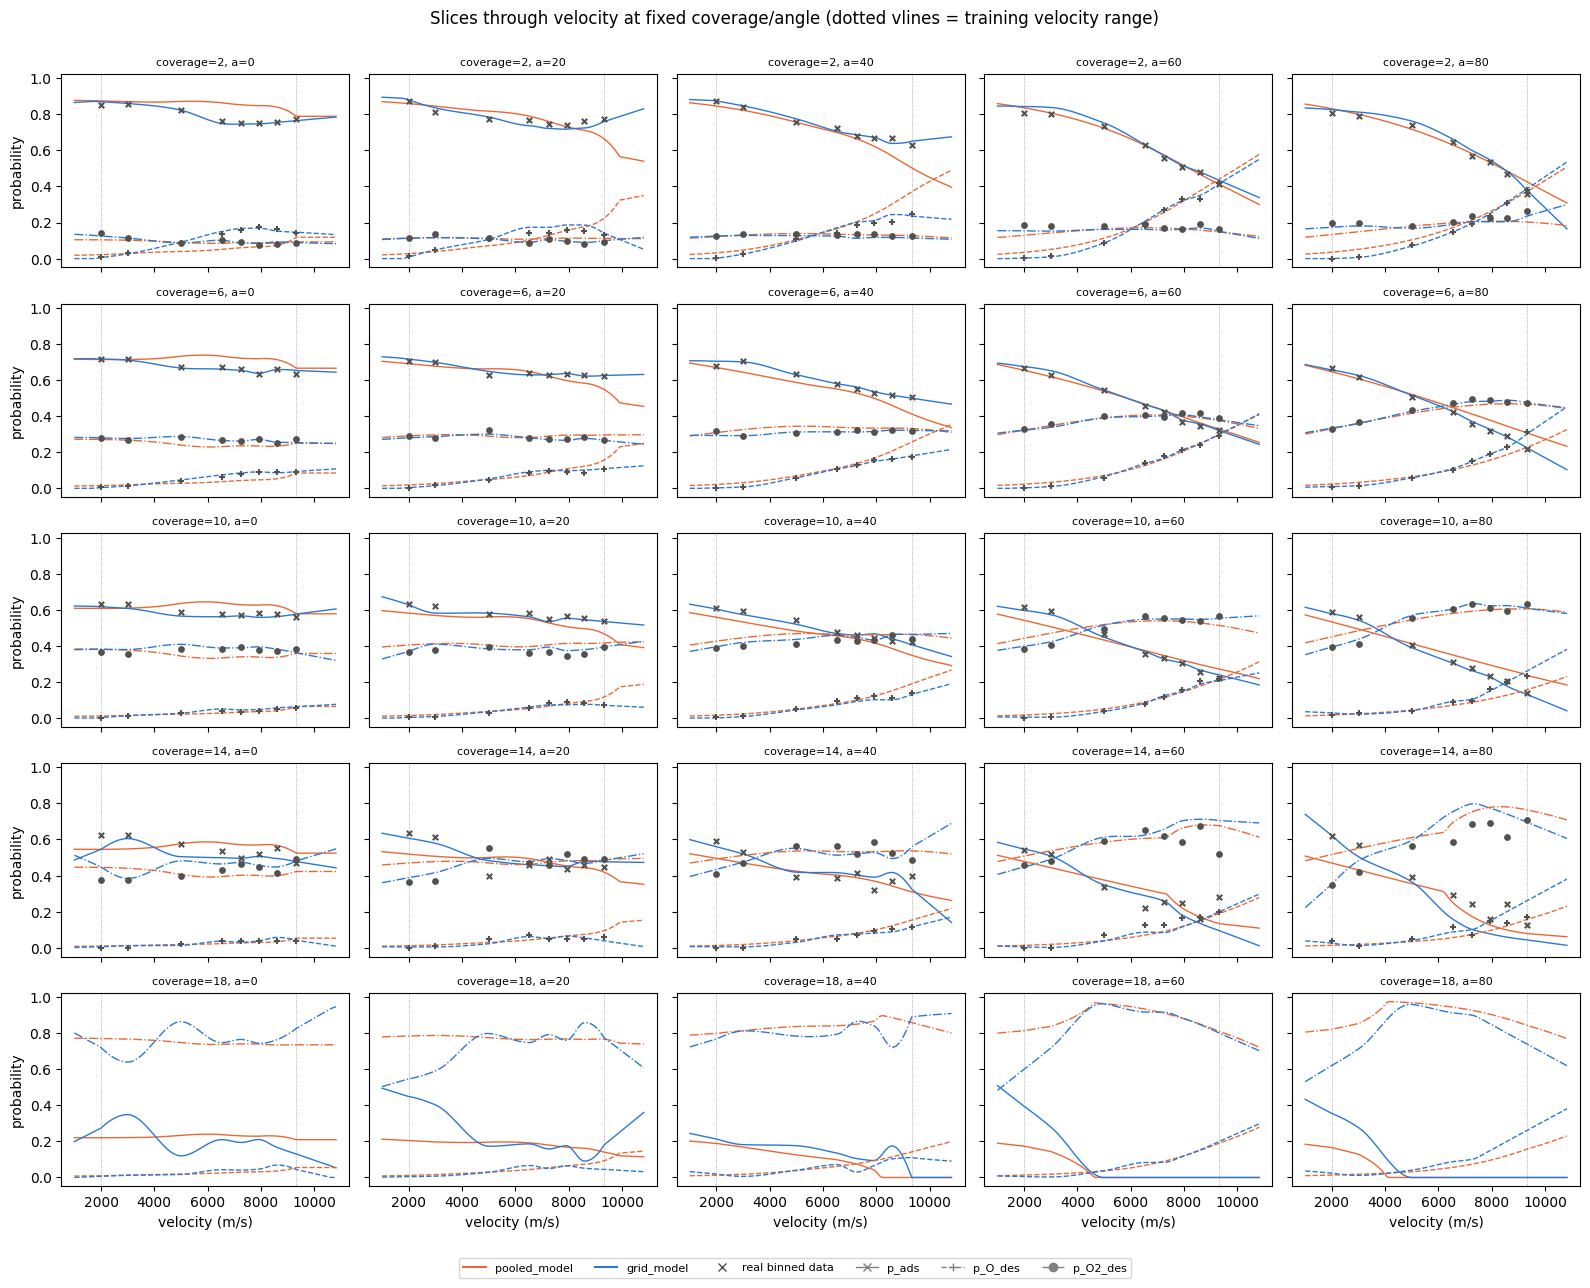

In [7]:
# fixed coverage values to slice through, spanning the range used in coverages_plot above
coverage_slices = [2, 6, 10, 14, 18]

# cache real binned data once per (velocity, angle) -- reused by the angle-slice cell below
real_data_cache = {(v, a): bin_real(df, v, a) for v in real_velocities for a in real_angles}

velocities_plot = np.linspace(min(real_velocities) - 1000, max(real_velocities) + 1500, 100)

fig, axes = plt.subplots(len(coverage_slices), len(real_angles),
                          figsize=(3.2 * len(real_angles), 2.6 * len(coverage_slices)),
                          sharex=True, sharey=True)

for ci, coverage in enumerate(coverage_slices):
    for ai, angle_check in enumerate(real_angles):
        ax = axes[ci, ai]
        pooled_probs = np.array([pooled_model.probs(coverage, v, angle_check) for v in velocities_plot])
        grid_probs = np.array([grid_model.eval(np.array([coverage]), [v, angle_check]) for v in velocities_plot])
        for k in range(3):
            ax.plot(velocities_plot, pooled_probs[:, k], LINESTYLES[k], color=POOLED_COLOR, linewidth=1)
            ax.plot(velocities_plot, grid_probs[:, k], LINESTYLES[k], color=GRID_COLOR, linewidth=1)
            xs, ys = [], []
            for velocity_check in real_velocities:
                centers, real_probs = real_data_cache[(velocity_check, angle_check)]
                if coverage in centers:
                    xs.append(velocity_check)
                    ys.append(real_probs[list(centers).index(coverage), k])
            ax.scatter(xs, ys, color=REAL_COLOR, marker=MARKERS[k], s=15, zorder=5)
        ax.axvline(min(real_velocities), color="gray", lw=0.5, ls=":")
        ax.axvline(max(real_velocities), color="gray", lw=0.5, ls=":")
        ax.set_title(f"coverage={coverage}, a={angle_check:.0f}", fontsize=8)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
for ax in axes[-1, :]:
    ax.set_xlabel("velocity (m/s)")

legend_handles = (
    [plt.Line2D([0], [0], color=POOLED_COLOR, lw=1.5, label="pooled_model"),
     plt.Line2D([0], [0], color=GRID_COLOR, lw=1.5, label="grid_model"),
     plt.Line2D([0], [0], color=REAL_COLOR, marker="x", ls="", label="real binned data")]
    + [plt.Line2D([0], [0], color="gray", ls=LINESTYLES[k], marker=MARKERS[k], lw=1, label=labels[k])
       for k in range(3)]
)
fig.legend(handles=legend_handles, loc="lower center", ncol=6, fontsize=8, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("Slices through velocity at fixed coverage/angle "
             "(dotted vlines = training velocity range)")
plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.savefig("hyper_plots/velocity_slices.png", dpi=300)
plt.show()

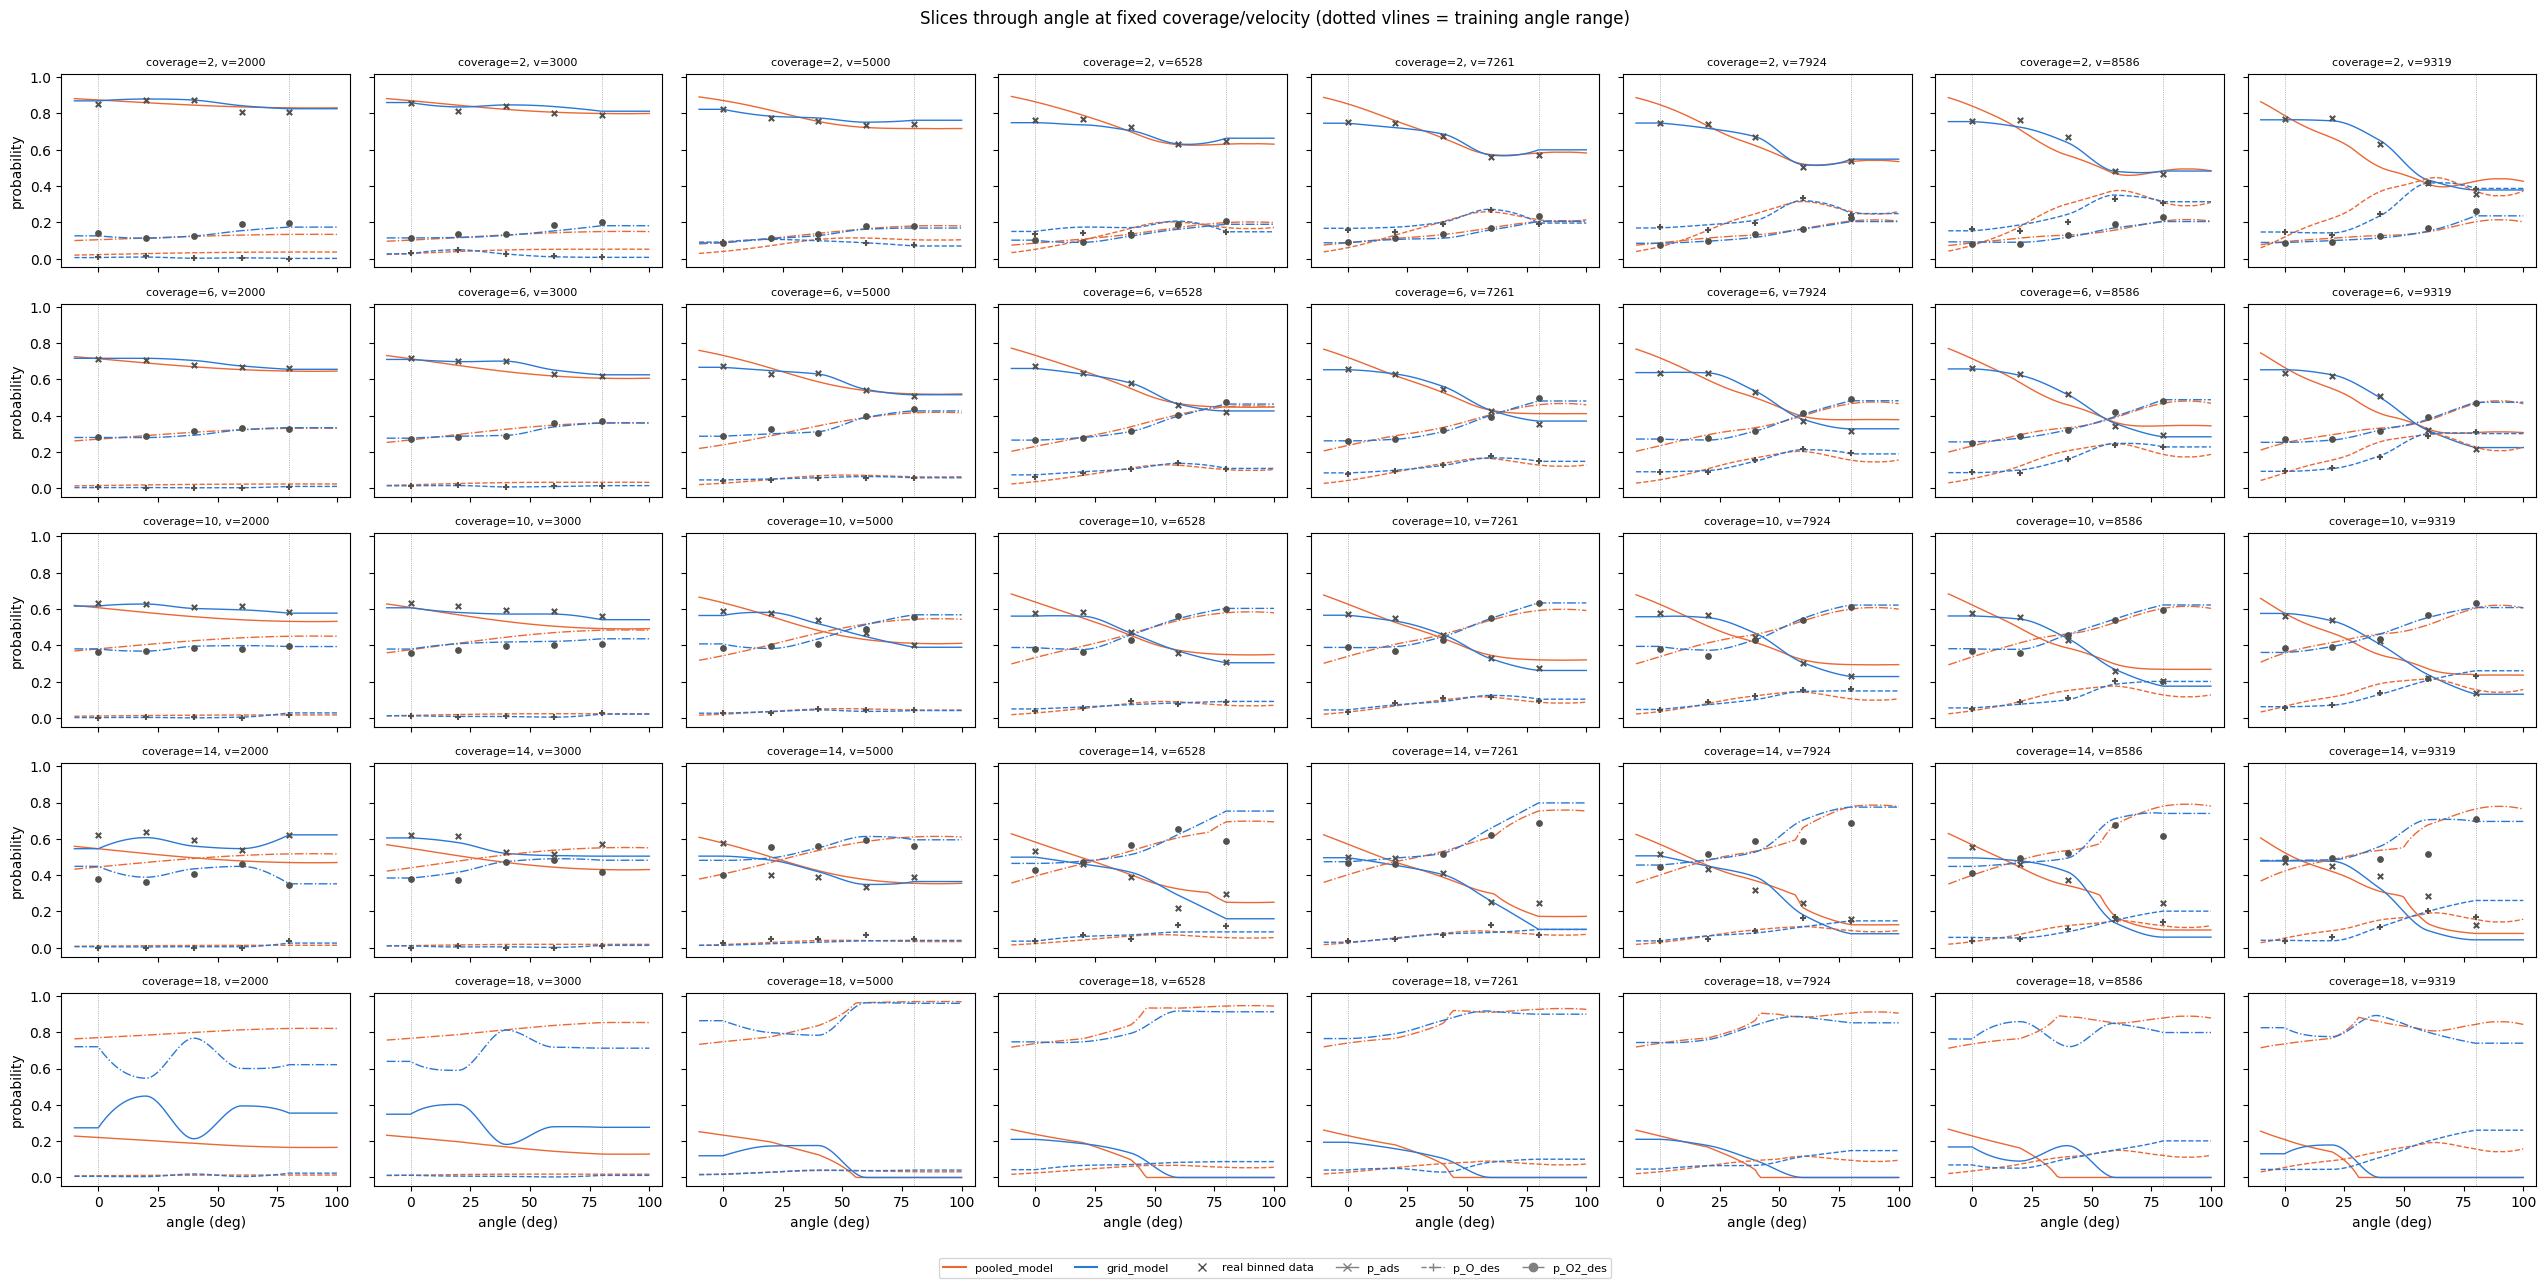

In [8]:
angles_plot = np.linspace(min(real_angles) - 10, max(real_angles) + 20, 100)

fig, axes = plt.subplots(len(coverage_slices), len(real_velocities),
                          figsize=(3.2 * len(real_velocities), 2.6 * len(coverage_slices)),
                          sharex=True, sharey=True)

for ci, coverage in enumerate(coverage_slices):
    for vi, velocity_check in enumerate(real_velocities):
        ax = axes[ci, vi]
        pooled_probs = np.array([pooled_model.probs(coverage, velocity_check, a) for a in angles_plot])
        grid_probs = np.array([grid_model.eval(np.array([coverage]), [velocity_check, a]) for a in angles_plot])
        for k in range(3):
            ax.plot(angles_plot, pooled_probs[:, k], LINESTYLES[k], color=POOLED_COLOR, linewidth=1)
            ax.plot(angles_plot, grid_probs[:, k], LINESTYLES[k], color=GRID_COLOR, linewidth=1)
            xs, ys = [], []
            for angle_check in real_angles:
                centers, real_probs = real_data_cache[(velocity_check, angle_check)]
                if coverage in centers:
                    xs.append(angle_check)
                    ys.append(real_probs[list(centers).index(coverage), k])
            ax.scatter(xs, ys, color=REAL_COLOR, marker=MARKERS[k], s=15, zorder=5)
        ax.axvline(min(real_angles), color="gray", lw=0.5, ls=":")
        ax.axvline(max(real_angles), color="gray", lw=0.5, ls=":")
        ax.set_title(f"coverage={coverage}, v={velocity_check:.0f}", fontsize=8)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
for ax in axes[-1, :]:
    ax.set_xlabel("angle (deg)")

legend_handles = (
    [plt.Line2D([0], [0], color=POOLED_COLOR, lw=1.5, label="pooled_model"),
     plt.Line2D([0], [0], color=GRID_COLOR, lw=1.5, label="grid_model"),
     plt.Line2D([0], [0], color=REAL_COLOR, marker="x", ls="", label="real binned data")]
    + [plt.Line2D([0], [0], color="gray", ls=LINESTYLES[k], marker=MARKERS[k], lw=1, label=labels[k])
       for k in range(3)]
)
fig.legend(handles=legend_handles, loc="lower center", ncol=6, fontsize=8, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("Slices through angle at fixed coverage/velocity "
             "(dotted vlines = training angle range)")
plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.savefig("hyper_plots/angle_slices.png", dpi=300)
plt.show()

## Per-condition fit vs. real data, with self-consistent ceiling

A more detailed per-condition view: continuous coverage axis well past
`N_SITES` so the extrapolated/blended tail and each condition's ceiling are
visible on the same axis, with sparse (< `min_bin` samples) bins shown in a
darker shade rather than dropped.

In [9]:
def bin_actual_probs(df, velocity, angle):
    """Per-coverage outcome probabilities and sample counts for one
    (velocity, angle) condition. Keeps every coverage bin, including
    low-count ones -- plot_fit_grid colors bins below MIN_BIN darker rather
    than dropping them, so sparse (noisier) data stays visible but visually
    distinguished from trusted bins."""
    sub = df[np.isclose(df["velocity"], velocity) & np.isclose(df["angle"], angle)]
    by_cov = sub.groupby("coverage")["n_atoms"].agg(
        count="count",
        p_ads=lambda s: (s == 0).mean(),
        p_O_des=lambda s: (s == 1).mean(),
        p_O2_des=lambda s: (s == 2).mean(),
    ).reset_index()
    return by_cov.sort_values("coverage")


def eval_model_probs(model, coverage, velocity, angle):
    """Dispatch a single (coverage, velocity, angle) query to whichever
    calling convention this model uses: PooledCoverageModel.probs(c, *cond)
    or GridClassifier.eval(feature, axis_query)."""
    if hasattr(model, "probs"):
        return model.probs(coverage, velocity, angle)
    return model.eval(np.array([coverage]), [velocity, angle])


def model_ceiling(model, velocity, angle):
    """This condition's self-consistent MC blend ceiling, if the model
    tracks one: PooledCoverageModel via its interpolated ceiling_grid
    (queried exactly at a sampled grid point here), GridClassifier via its
    per-cell CoverageCell.ceiling. None if neither applies."""
    vi = real_velocities.index(velocity)
    ai = real_angles.index(angle)
    if getattr(model, "ceiling_grid", None) is not None:
        return float(model.ceiling_grid[vi, ai])
    if hasattr(model, "cell_classifiers"):
        return float(model.cell_classifiers[(vi, ai)].ceiling)
    return None


def plot_fit_grid(models, title=None, x_max=55, min_bin=20, velocities=None, angles=None):
    """models: a single model, or a {label: model} dict to overlay for
    comparison. One panel per (velocity, angle) sampled condition,
    continuous coverage axis [0, x_max] -- comfortably past N_SITES so the
    extrapolated/blended tail and any ceiling are visible on the same axis.
    Dots = actual binned probability (dark shade below min_bin samples).
    Ported from coverage_experiment/coverage_model's plot_fit_grid, adapted
    to coverage_kernel's PooledCoverageModel/GridClassifier calling
    conventions via eval_model_probs/model_ceiling.

    velocities/angles restrict which panels are drawn (default: the full
    real_velocities x real_angles grid) -- model_ceiling still indexes
    against the full real_velocities/real_angles lists regardless, so a
    subset here just selects which cells of that grid to show.
    """
    if not isinstance(models, dict):
        models = {None: models}
    linestyles = ["--", ":", "-."]
    velocities = real_velocities if velocities is None else velocities
    angles = real_angles if angles is None else angles

    OUTCOMES = ["p_ads", "p_O_des", "p_O2_des"]
    COLORS = {"p_ads": "#4C72B0", "p_O_des": "#DD8452", "p_O2_des": "#55A868"}
    DARK_COLORS = {"p_ads": "#1B3A63", "p_O_des": "#8A4113", "p_O2_des": "#255C33"}
    LABELS = {"p_ads": "Adsorption", "p_O_des": "O desorption", "p_O2_des": "O$_2$ desorption"}

    fig, axes = plt.subplots(len(velocities), len(angles),
                              figsize=(len(angles) * 3.2, len(velocities) * 2.2),
                              sharex=True, sharey=True, squeeze=False)
    x_fit = np.linspace(0, x_max, 200)

    for row_i, velocity in enumerate(velocities):
        for col_i, angle in enumerate(angles):
            ax = axes[row_i, col_i]

            by_cov = bin_actual_probs(df, velocity, angle)
            cov_max = by_cov["coverage"].max() if len(by_cov) else 1

            ceiling = None
            for model in models.values():
                c = model_ceiling(model, velocity, angle)
                if c is not None:
                    ceiling = c
                    break

            if len(by_cov):
                trusted = by_cov["count"] >= min_bin
                for outcome in OUTCOMES:
                    ax.scatter(by_cov.loc[trusted, "coverage"], by_cov.loc[trusted, outcome],
                               color=COLORS[outcome], s=10, zorder=3)
                    ax.scatter(by_cov.loc[~trusted, "coverage"], by_cov.loc[~trusted, outcome],
                               color=DARK_COLORS[outcome], s=10, zorder=3)
                ax.axvspan(cov_max, x_max, color="grey", alpha=0.08)

            for model_i, (label, model) in enumerate(models.items()):
                y_fit = np.array([eval_model_probs(model, c, velocity, angle) for c in x_fit])
                ls = linestyles[model_i % len(linestyles)]
                for j, outcome in enumerate(OUTCOMES):
                    ax.plot(x_fit, y_fit[:, j], color=COLORS[outcome], linewidth=1.2, linestyle=ls, zorder=2)

            ax.axvline(N_SITES, color="grey", linewidth=0.8, linestyle=":", zorder=1)
            if ceiling is not None:
                ax.axvline(ceiling, color="black", linewidth=1.0, linestyle="-", alpha=0.6, zorder=1)
                ax.text(0.97, 0.95, f"ceil={ceiling:.0f}", transform=ax.transAxes,
                        ha="right", va="top", fontsize=6.5, color="#444444")

            ax.set_xlim(0, x_max)
            ax.set_ylim(-0.02, 1.02)
            ax.grid(linestyle="--", alpha=0.3)
            ax.tick_params(labelsize=7)

            if row_i == 0:
                ax.set_title(f"a = {angle:.0f} deg", fontsize=11, fontweight="bold")
            if col_i == 0:
                ax.set_ylabel(f"{velocity:.0f}\nm/s", fontsize=9, fontweight="bold",
                              rotation=0, labelpad=28, va="center")
            if row_i == len(velocities) - 1:
                ax.set_xlabel("Coverage", fontsize=9)

    outcome_legend = [
        plt.Line2D([0], [0], marker="o", linestyle="none", color=COLORS[o], label=LABELS[o], markersize=5)
        for o in OUTCOMES
    ]
    outcome_legend.append(
        plt.Line2D([0], [0], marker="o", linestyle="none", color="#555555",
                   label=f"< {min_bin} samples in bin", markersize=5)
    )
    model_labels = [label for label in models if label is not None]
    model_legend = [
        plt.Line2D([0], [0], linestyle=linestyles[i % len(linestyles)], color="black", label=label)
        for i, label in enumerate(model_labels)
    ]
    fig.legend(handles=outcome_legend + model_legend, loc="lower center",
               bbox_to_anchor=(0.5, -0.015), ncol=len(outcome_legend) + len(model_legend),
               fontsize=11, framealpha=0.9)
    
    if title is not None:
        fig.suptitle(title, fontsize=13, fontweight="bold")
        
    fig.tight_layout(rect=[0, 0.02, 1, 0.96])
    return fig

Saved hyper_plots/fit_grid.pdf and hyper_plots/fit_grid.png


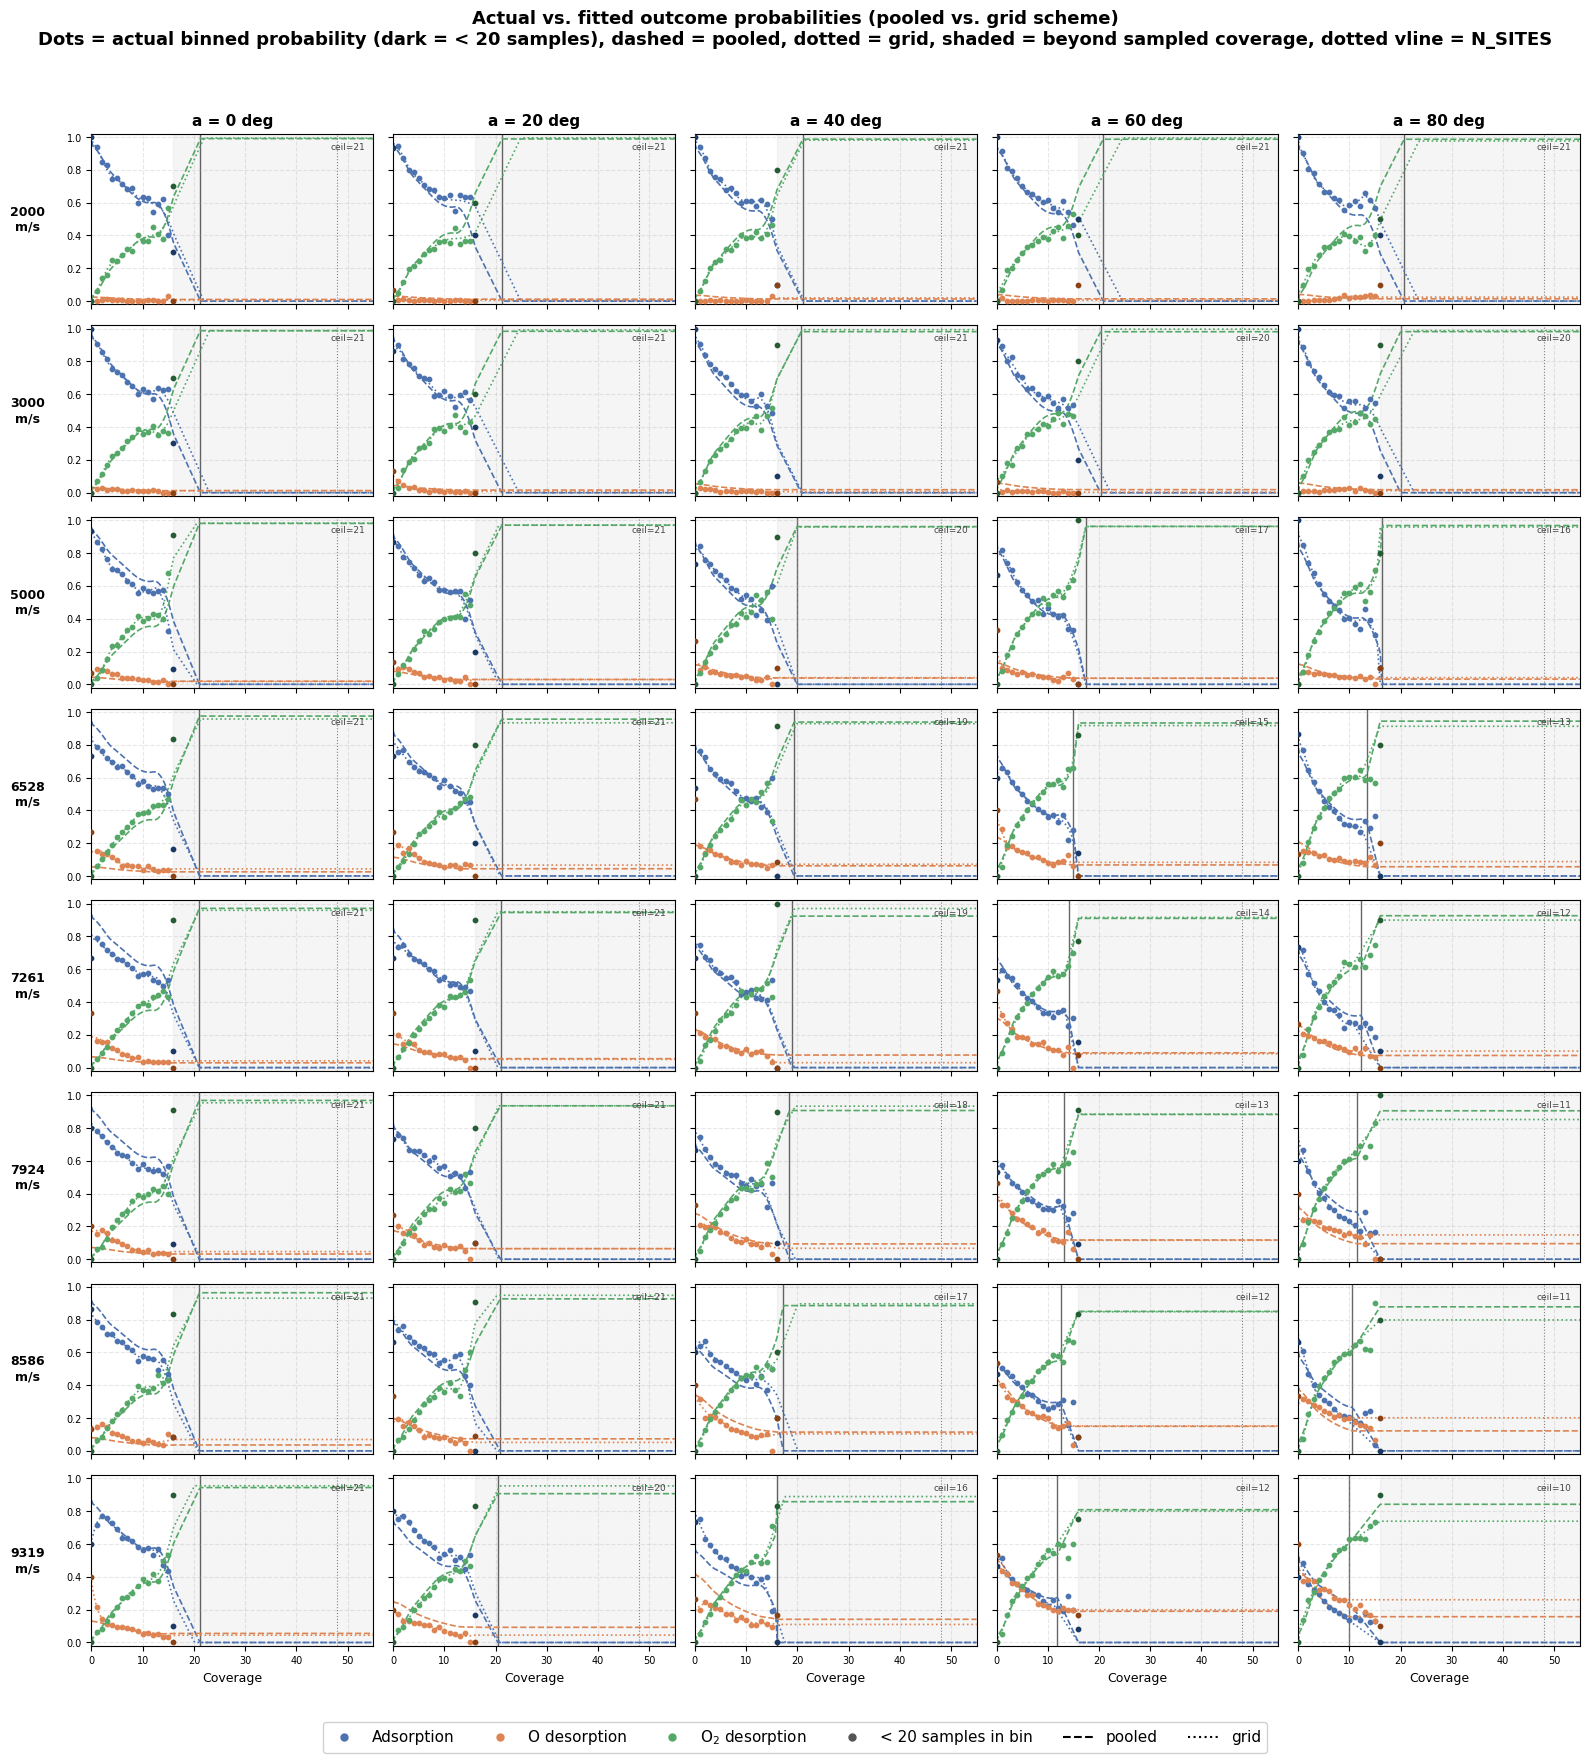

In [10]:
Path("hyper_plots").mkdir(exist_ok=True)

fig = plot_fit_grid(
    {"pooled": pooled_model, "grid": grid_model},
    "Actual vs. fitted outcome probabilities (pooled vs. grid scheme)\n"
    "Dots = actual binned probability (dark = < 20 samples), dashed = pooled, dotted = grid, "
    "shaded = beyond sampled coverage, dotted vline = N_SITES",
)
fig.savefig("hyper_plots/fit_grid.pdf", bbox_inches="tight")
fig.savefig("hyper_plots/fit_grid.png", dpi=300, bbox_inches="tight")
print("Saved hyper_plots/fit_grid.pdf and hyper_plots/fit_grid.png")
plt.show()

Saved hyper_plots/fit_grid_zoom.pdf and hyper_plots/fit_grid_zoom.png


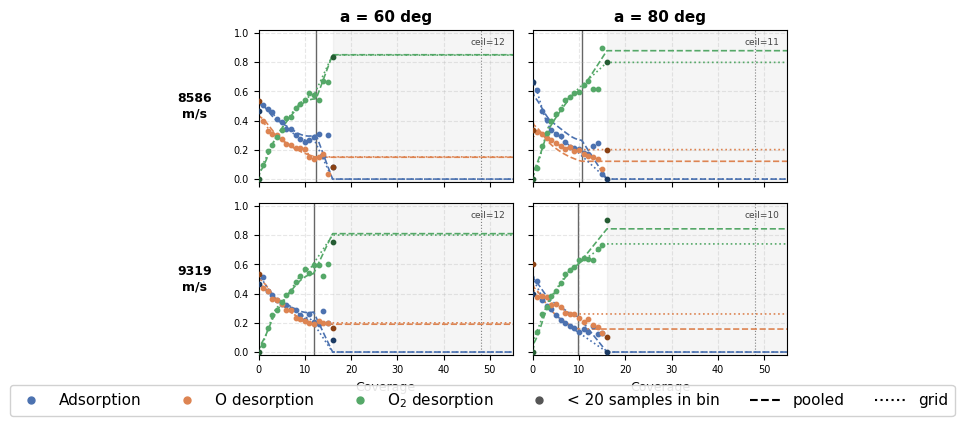

In [11]:
# Zoomed-in fit_grid: just the bottom-right 2x2 block of the full grid above
# -- the two highest velocities (~8586, ~9319 m/s) x the two highest angles
# (60, 80 deg).
velocities_zoom = real_velocities[-2:]
angles_zoom = real_angles[-2:]

fig_zoom = plot_fit_grid(
    {"pooled": pooled_model, "grid": grid_model},
    velocities=velocities_zoom, angles=angles_zoom,
)
fig_zoom.savefig("hyper_plots/fit_grid_zoom.pdf", bbox_inches="tight")
fig_zoom.savefig("hyper_plots/fit_grid_zoom.png", dpi=300, bbox_inches="tight")
print("Saved hyper_plots/fit_grid_zoom.pdf and hyper_plots/fit_grid_zoom.png")
plt.show()

## Stacked-area view of outcome probabilities

Same real-data outcome probabilities as `bin_actual_probs` above, at a
representative 2x2 (velocity, angle) subset, as a stacked-area chart
instead of separate per-outcome curves.

Saved hyper_plots/outcome_stacked_grid_zoom.pdf and .png


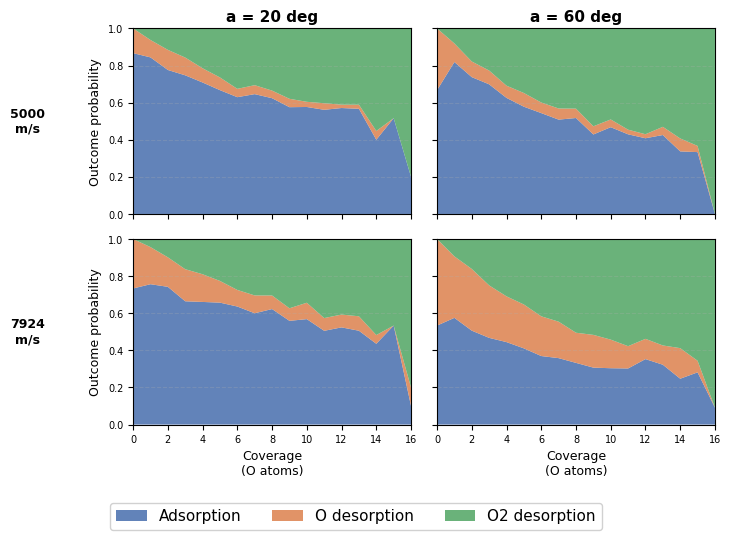

In [12]:
from matplotlib.patches import Patch

velocities_stack = sorted({min(real_velocities, key=lambda v: abs(v - target)) for target in (5000, 7800)})
angles_stack = sorted({min(real_angles, key=lambda a: abs(a - target)) for target in (20, 60)})

STACK_COLORS = {"p_ads": "#4C72B0", "p_O_des": "#DD8452", "p_O2_des": "#55A868"}
STACK_LABELS = {"p_ads": "Adsorption", "p_O_des": "O desorption", "p_O2_des": "O2 desorption"}

fig_stack, axes_stack = plt.subplots(len(velocities_stack), len(angles_stack),
                                      figsize=(len(angles_stack) * 3.8, len(velocities_stack) * 2.8),
                                      sharex=True, sharey=True, squeeze=False)

for row_i, velocity in enumerate(velocities_stack):
    for col_i, angle in enumerate(angles_stack):
        ax = axes_stack[row_i, col_i]
        by_cov = bin_actual_probs(df, velocity, angle)

        ax.stackplot(
            by_cov["coverage"], by_cov["p_ads"], by_cov["p_O_des"], by_cov["p_O2_des"],
            colors=[STACK_COLORS["p_ads"], STACK_COLORS["p_O_des"], STACK_COLORS["p_O2_des"]],
            alpha=0.88,
        )
        ax.set_xlim(0, 16)
        ax.set_ylim(0, 1)
        ax.grid(axis="y", linestyle="--", alpha=0.25)
        ax.tick_params(labelsize=7)

        if row_i == 0:
            ax.set_title(f"a = {angle:.0f} deg", fontsize=11, fontweight="bold", pad=5)
        if col_i == 0:
            ax.set_ylabel("Outcome probability", fontsize=9)
            ax.text(-0.38, 0.5, f"{velocity:.0f}\nm/s", transform=ax.transAxes,
                    fontsize=9, fontweight="bold", rotation=0, va="center", ha="center")
        if row_i == len(velocities_stack) - 1:
            ax.set_xlabel("Coverage\n(O atoms)", fontsize=9)

legend_elements = [Patch(facecolor=STACK_COLORS[k], alpha=0.88, label=STACK_LABELS[k]) for k in STACK_COLORS]
fig_stack.legend(handles=legend_elements, loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=3,
                  fontsize=11, framealpha=0.9)

fig_stack.tight_layout(rect=[0.03, 0.04, 1, 0.93])
fig_stack.savefig("hyper_plots/outcome_stacked_grid_zoom.pdf", bbox_inches="tight")
fig_stack.savefig("hyper_plots/outcome_stacked_grid_zoom.png", dpi=200, bbox_inches="tight")
print("Saved hyper_plots/outcome_stacked_grid_zoom.pdf and .png")
plt.show()

## Save both fitted models

In [13]:
from coverage_kernel.export_hdf5 import export_pooled_model, export_grid_model

Path("models").mkdir(exist_ok=True)
export_pooled_model("models/pooled_model.h5", pooled_model, coverage_delta=COVERAGE_DELTA)
export_grid_model("models/grid_model.h5", grid_model, coverage_delta=COVERAGE_DELTA)
print("saved models/pooled_model.h5 and models/grid_model.h5")

saved models/pooled_model.h5 and models/grid_model.h5
